In [1]:
import sqlite3
import pandas as pd

csv_file = 'OnlineRetail.csv'
db_file = 'ecommerce_data.db'
table_name = 'transactions'
print("Reading CSV file...")
df = pd.read_csv(csv_file, encoding='ISO-8859-1')

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print("Successfully converted 'InvoiceDate' column to a standard format.")

print(f"Connecting to database '{db_file}'...")
conn = sqlite3.connect(db_file)

print(f"Loading cleaned data into SQL table '{table_name}'...")
df.to_sql(table_name, conn, if_exists='replace', index=False)

conn.close()
print("\nSuccess! The database has been created with clean, standardized dates.")

Reading CSV file...


Successfully converted 'InvoiceDate' column to a standard format.
Connecting to database 'ecommerce_data.db'...
Loading cleaned data into SQL table 'transactions'...



Success! The database has been created with clean, standardized dates.


In [2]:
import pandas as pd
import sqlite3

db_file = 'ecommerce_data.db'
conn = sqlite3.connect(db_file)

rfm_query = """
WITH
    -- Find the snapshot date, which is one day after the last transaction in the whole dataset
    snapshot AS (
        SELECT date(MAX(InvoiceDate), '+1 day') AS snapshot_date
        FROM transactions
    ),
    -- Calculate raw RFM metrics for each customer
    rfm_metrics AS (
        SELECT
            CustomerID,
            MAX(date(InvoiceDate)) AS last_purchase_date,
            COUNT(DISTINCT InvoiceNo) AS Frequency,
            SUM(Quantity * UnitPrice) AS MonetaryValue
        FROM
            transactions
        WHERE
            CustomerID IS NOT NULL AND Quantity > 0 AND UnitPrice > 0
        GROUP BY
            CustomerID
    )
-- Final SELECT: Calculate Recency by comparing to the snapshot_date
SELECT
    m.CustomerID,
    (julianday(s.snapshot_date) - julianday(m.last_purchase_date)) AS Recency,
    m.Frequency,
    m.MonetaryValue
FROM
    rfm_metrics m, snapshot s;
"""

print("Executing the final, corrected RFM query...")
rfm_df = pd.read_sql_query(rfm_query, conn)
conn.close()

print("\n--- FINAL CORRECTED RFM DATA ---")
# Now you will see logical, positive Recency values (e.g., 10, 50, 373)
print(rfm_df.head())

Executing the final, corrected RFM query...



--- FINAL CORRECTED RFM DATA ---
   CustomerID  Recency  Frequency  MonetaryValue
0     12346.0    326.0          1       77183.60
1     12347.0      3.0          7        4310.00
2     12348.0     76.0          4        1797.24
3     12349.0     19.0          1        1757.55
4     12350.0    311.0          1         334.40


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

if 'CustomerID' in rfm_df.columns:
    rfm_df.set_index('CustomerID', inplace=True)

print("Part 1: Scaling the corrected RFM data...")
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_df)
rfm_scaled = pd.DataFrame(rfm_scaled, index=rfm_df.index, columns=rfm_df.columns)
print("original")
print(rfm_df.head())
print("Scaling complete.")
print(rfm_scaled.head())

Part 1: Scaling the corrected RFM data...
original
            Recency  Frequency  MonetaryValue
CustomerID                                   
12346.0       326.0          1       77183.60
12347.0         3.0          7        4310.00
12348.0        76.0          4        1797.24
12349.0        19.0          1        1757.55
12350.0       311.0          1         334.40
Scaling complete.
             Recency  Frequency  MonetaryValue
CustomerID                                    
12346.0     2.329388  -0.425097       8.358668
12347.0    -0.900588   0.354417       0.250966
12348.0    -0.170593  -0.035340      -0.028596
12349.0    -0.740589  -0.425097      -0.033012
12350.0     2.179389  -0.425097      -0.191347


In [4]:

# --- Part 2: Hybrid Clustering ---
print("\nPart 2: Running Hybrid Clustering...")

dbscan = DBSCAN(eps=0.8, min_samples=15)
dbscan.fit(rfm_scaled)
rfm_df['Is_Outlier'] = dbscan.labels_
rfm_df['Is_Outlier'] = rfm_df['Is_Outlier'].apply(lambda x: 1 if x == -1 else 0)

core_customers_df = rfm_df[rfm_df['Is_Outlier'] == 0].copy()
core_customers_scaled = rfm_scaled[rfm_df['Is_Outlier'] == 0].copy()
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(core_customers_scaled)
core_customers_df['Cluster'] = kmeans.labels_

rfm_df['Cluster'] = core_customers_df['Cluster']
rfm_df['Cluster'] = rfm_df['Cluster'].fillna(3) 
rfm_df['Cluster'] = rfm_df['Cluster'].astype(int)
rfm_df.drop(columns=['Is_Outlier'], inplace=True)
print("\nHybrid Clustering Complete. Final Distribution:")
print(rfm_df['Cluster'].value_counts().sort_index())




Part 2: Running Hybrid Clustering...



Hybrid Clustering Complete. Final Distribution:
Cluster
0    2861
1    1053
2     373
3      51
Name: count, dtype: int64


In [5]:
# --- Part 3: Validate the Clusters ---
print("\nPart 3: Validating the core clusters...")
score = silhouette_score(core_customers_scaled, kmeans.labels_)
print(f"--> Silhouette Score: {score:.4f} (A score above 0.5 is strong)")


Part 3: Validating the core clusters...


--> Silhouette Score: 0.5807 (A score above 0.5 is strong)


In [6]:
# --- Part 4: Final Profile Analysis ---
print("\nPart 4: Calculating final segment profiles...")
segment_profile = rfm_df.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'MonetaryValue': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'CustomerCount'})
segment_profile = segment_profile.round(2)

print("\n--- FINAL SEGMENT PROFILE ---")
print(segment_profile.sort_values(by='MonetaryValue', ascending=False))


Part 4: Calculating final segment profiles...

--- FINAL SEGMENT PROFILE ---
         Recency  Frequency  MonetaryValue  CustomerCount
Cluster                                                  
3          29.86      45.94       56716.04             51
2          15.36      14.92        5922.97            373
0          46.57       3.14        1155.78           2861
1         249.95       1.55         477.63           1053


In [7]:
rfm_df.to_csv('customer_segments_final.csv')
print("Final segmented data has been saved to 'customer_segments_final.csv'")

Final segmented data has been saved to 'customer_segments_final.csv'


## Charts
The same charts as the dashboard website. Run the cells above first, because these use `rfm_df`.

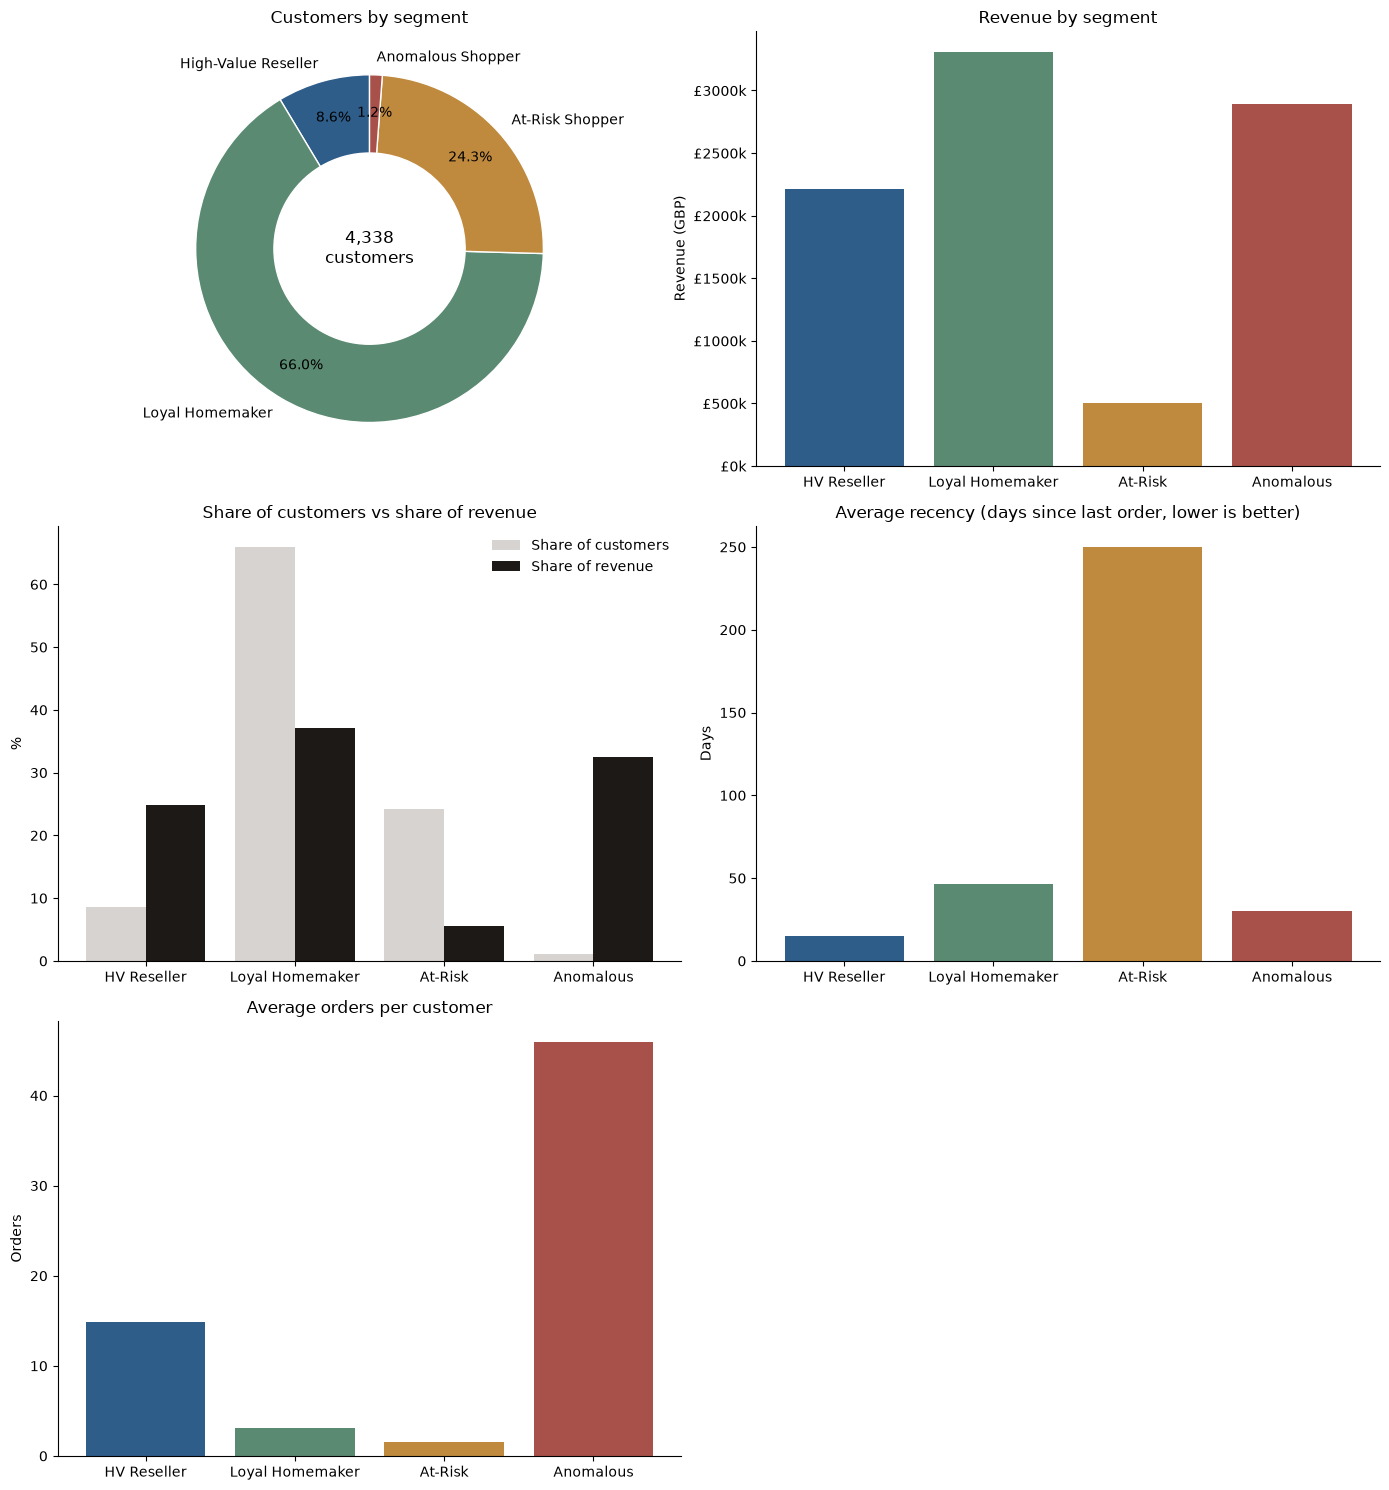

In [8]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# Cluster ids -> persona names (matches the README and the website)
names = {2: "High-Value Reseller", 0: "Loyal Homemaker", 1: "At-Risk Shopper", 3: "Anomalous Shopper"}
colors = {2: "#2f5d8a", 0: "#5b8a72", 1: "#c08a3e", 3: "#a8514a"}
order = [2, 0, 1, 3]

seg = rfm_df.groupby("Cluster").agg(
    customers=("Recency", "size"),
    revenue=("MonetaryValue", "sum"),
    avg_recency=("Recency", "mean"),
    avg_orders=("Frequency", "mean"),
).loc[order]
seg["customer_share"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum() * 100

labels = [names[c] for c in seg.index]
short = [n.replace(" Shopper", "").replace("High-Value ", "HV ") for n in labels]
cols = [colors[c] for c in seg.index]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# 1. Customers by segment
ax = axes[0, 0]
ax.pie(seg["customers"], labels=labels, colors=cols, autopct="%1.1f%%", startangle=90,
       wedgeprops={"width": 0.45, "edgecolor": "white"}, pctdistance=0.78)
ax.set_title("Customers by segment")
ax.text(0, 0, f"{int(seg['customers'].sum()):,}\ncustomers", ha="center", va="center", fontsize=12)

# 2. Revenue by segment
ax = axes[0, 1]
ax.bar(short, seg["revenue"], color=cols)
ax.set_title("Revenue by segment")
ax.set_ylabel("Revenue (GBP)")
ax.yaxis.set_major_formatter(lambda v, _: f"£{v/1000:.0f}k")

# 3. Share of customers vs share of revenue
ax = axes[1, 0]
x = np.arange(len(short))
ax.bar(x - 0.2, seg["customer_share"], 0.4, label="Share of customers", color="#d6d3d1")
ax.bar(x + 0.2, seg["revenue_share"], 0.4, label="Share of revenue", color="#1c1917")
ax.set_xticks(x)
ax.set_xticklabels(short)
ax.set_ylabel("%")
ax.set_title("Share of customers vs share of revenue")
ax.legend(frameon=False)

# 4. Average recency
ax = axes[1, 1]
ax.bar(short, seg["avg_recency"], color=cols)
ax.set_title("Average recency (days since last order, lower is better)")
ax.set_ylabel("Days")

# 5. Average orders per customer
ax = axes[2, 0]
ax.bar(short, seg["avg_orders"], color=cols)
ax.set_title("Average orders per customer")
ax.set_ylabel("Orders")

axes[2, 1].axis("off")
plt.tight_layout()
plt.show()

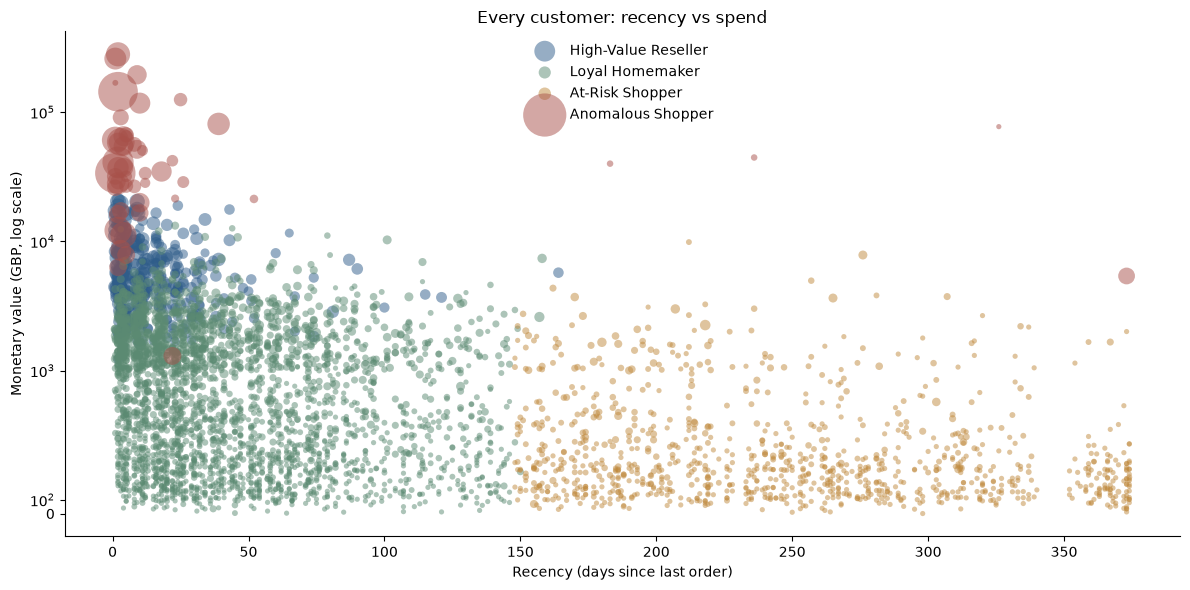

In [9]:
# 6. Every customer: recency vs spend (bubble size = order count)
fig, ax = plt.subplots(figsize=(12, 6))
for c in order:
    d = rfm_df[rfm_df["Cluster"] == c]
    ax.scatter(d["Recency"], d["MonetaryValue"], s=10 + d["Frequency"] * 4,
               color=colors[c], alpha=0.5, label=names[c], edgecolors="none")
ax.set_yscale("symlog", linthresh=1000)
ax.set_xlabel("Recency (days since last order)")
ax.set_ylabel("Monetary value (GBP, log scale)")
ax.set_title("Every customer: recency vs spend")
ax.legend(frameon=False, markerscale=1.5)
plt.tight_layout()
plt.show()